Do Hang Seng Index daily returns follow a normal distribution?

In [ ]:
!pip install yfinance

In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [ ]:
data = yf.download("^HSI", start="2016-01-01", end="2026-10-19",
                   auto_adjust=True, progress=False)
prices = data["Close"].squeeze()

print("Trading days downloaded:", len(prices))
print("First date:", prices.index[0].date())
print("Last date:", prices.index[-1].date())
print(prices.head())

Trading days downloaded: 2654
First date: 2016-01-04
Last date: 2026-10-16
Date
2016-01-04    21327.119141
2016-01-05    21188.720703
2016-01-06    20980.810547
2016-01-07    20333.339844
2016-01-08    20453.710938
Name: ^HSI, dtype: float64


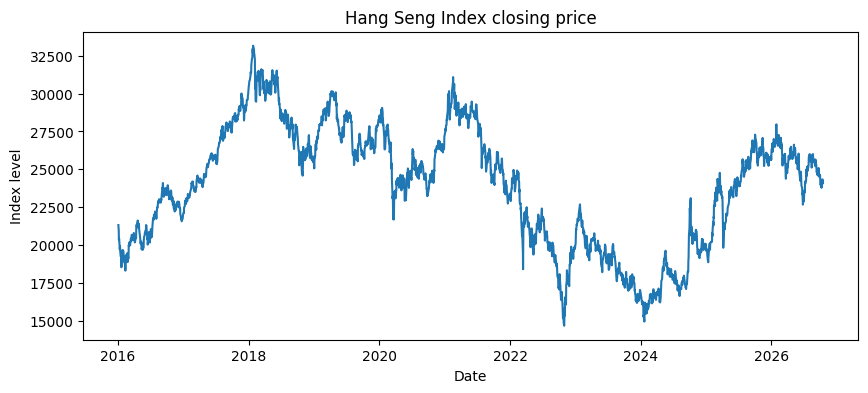

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(prices)
plt.title("Hang Seng Index closing price")
plt.xlabel("Date")
plt.ylabel("Index level")
plt.savefig("price_chart.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
returns = np.log(prices / prices.shift(1)).dropna()

print("Number of daily returns:", len(returns))
print(returns.head())

Number of daily returns: 2653
Date
2016-01-05   -0.006510
2016-01-06   -0.009861
2016-01-07   -0.031346
2016-01-08    0.005902
2016-01-11   -0.028023
Name: ^HSI, dtype: float64


In [ ]:
mean = returns.mean()
std = returns.std()
skew = stats.skew(returns)
kurt = stats.kurtosis(returns)   # "excess" kurtosis: a perfect bell curve = 0

print("Mean daily return:", round(float(mean), 5))
print("Standard deviation:", round(float(std), 5))
print("Skewness:", round(float(skew), 3))
print("Excess kurtosis:", round(float(kurt), 3))

print("\n5 worst days:")
print(returns.nsmallest(5))
print("\n5 best days:")
print(returns.nlargest(5))

Mean daily return: 5e-05
Standard deviation: 0.01377
Skewness: -0.371
Excess kurtosis: 7.154

5 worst days:
Date
2025-04-07   -0.141833
2024-10-08   -0.098793
2022-10-24   -0.065673
2022-03-15   -0.058867
2020-05-22   -0.057202
Name: ^HSI, dtype: float64

5 best days:
Date
2022-03-16    0.086928
2022-11-11    0.074548
2022-03-17    0.068012
2024-10-02    0.060143
2022-10-05    0.057368
Name: ^HSI, dtype: float64


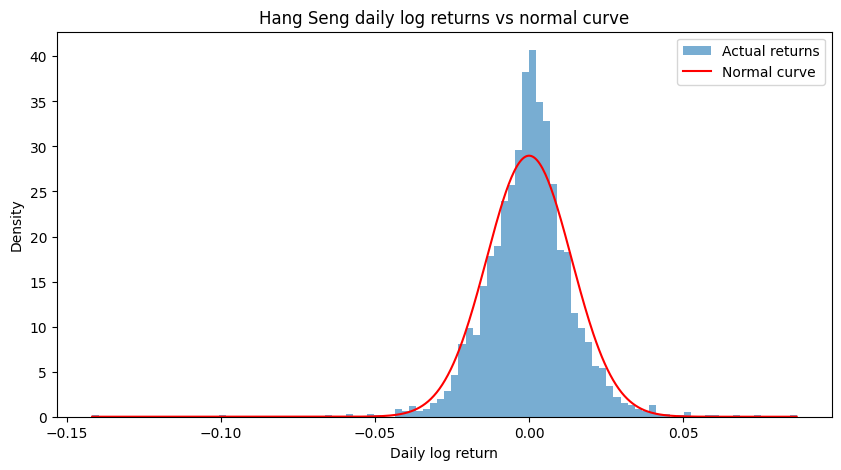

In [ ]:
plt.figure(figsize=(10, 5))
plt.hist(returns, bins=100, density=True, alpha=0.6, label="Actual returns")
x = np.linspace(returns.min(), returns.max(), 500)
plt.plot(x, stats.norm.pdf(x, mean, std), color="red", label="Normal curve")
plt.title("Hang Seng daily log returns vs normal curve")
plt.xlabel("Daily log return")
plt.ylabel("Density")
plt.legend()
plt.savefig("histogram.png", dpi=150, bbox_inches="tight")
plt.show()

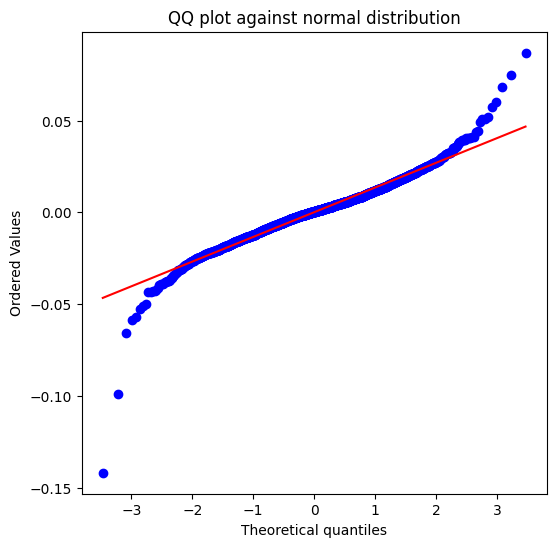

In [ ]:
plt.figure(figsize=(6, 6))
stats.probplot(returns, dist="norm", plot=plt)
plt.title("QQ plot against normal distribution")
plt.savefig("qq_plot.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
z = (returns - mean) / std   # how many standard deviations each day is from average

n_extreme3 = int((z.abs() > 3).sum())
n_expected3 = len(returns) * 0.0027       # a bell curve puts ~0.27% of days beyond 3
n_extreme4 = int((z.abs() > 4).sum())
n_expected4 = len(returns) * 0.000063     # ~0.0063% of days beyond 4

print("Days beyond 3 standard deviations:", n_extreme3,
      "| expected if normal:", round(n_expected3, 1))
print("Days beyond 4 standard deviations:", n_extreme4,
      "| expected if normal:", round(n_expected4, 2))

Days beyond 3 standard deviations: 24 | expected if normal: 7.2
Days beyond 4 standard deviations: 10 | expected if normal: 0.17


In [ ]:
jb_stat, jb_p = stats.jarque_bera(returns)

print("Jarque-Bera statistic:", round(float(jb_stat), 2))
print("p-value:", jb_p)

Jarque-Bera statistic: 5718.45
p-value: 0.0


In [ ]:
summary = pd.DataFrame({
    "Measure": ["Trading days", "Mean daily return", "Standard deviation",
                "Skewness", "Excess kurtosis",
                "Days beyond 3 SD", "Expected beyond 3 SD (normal)",
                "Days beyond 4 SD", "Expected beyond 4 SD (normal)",
                "Jarque-Bera statistic", "Jarque-Bera p-value"],
    "Value": [len(returns), round(float(mean), 5), round(float(std), 5),
              round(float(skew), 3), round(float(kurt), 3),
              n_extreme3, round(n_expected3, 1),
              n_extreme4, round(n_expected4, 2),
              round(float(jb_stat), 2), jb_p]
})
print(summary.to_string(index=False))
summary.to_csv("results_summary.csv", index=False)

from google.colab import files
for f in ["price_chart.png", "histogram.png", "qq_plot.png", "results_summary.csv"]:
    files.download(f)

                      Measure      Value
                 Trading days 2653.00000
            Mean daily return    0.00005
           Standard deviation    0.01377
                     Skewness   -0.37100
              Excess kurtosis    7.15400
             Days beyond 3 SD   24.00000
Expected beyond 3 SD (normal)    7.20000
             Days beyond 4 SD   10.00000
Expected beyond 4 SD (normal)    0.17000
        Jarque-Bera statistic 5718.45000
          Jarque-Bera p-value    0.00000


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
S0 = float(prices.iloc[-1])           # latest index level
K = S0                                # strike price = today's level
T = 1.0                               # 1 year to expiry
r = 0.03                              # assumed risk-free rate
sigma = float(std) * np.sqrt(252)     # yearly volatility from your data

print("Starting index level (S0):", round(S0, 2))
print("Strike (K):", round(K, 2))
print("Yearly volatility (sigma):", round(sigma, 4))

Starting index level (S0): 24186.83
Strike (K): 24186.83
Yearly volatility (sigma): 0.2186


In [ ]:
from scipy.stats import norm

def monte_carlo_call(S0, K, T, r, sigma, n_paths, seed=42):
    rng = np.random.default_rng(seed)
    Z = rng.standard_normal(n_paths)
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    payoff = np.maximum(ST - K, 0)
    discounted = np.exp(-r * T) * payoff
    price = discounted.mean()
    std_error = discounted.std(ddof=1) / np.sqrt(n_paths)
    return price, std_error

def black_scholes_call(S0, K, T, r, sigma):
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

  Paths  Monte Carlo price  Standard error  Black-Scholes price  Absolute difference
    100            1746.02          247.91              2450.58               704.56
   1000            2308.22          113.91              2450.58               142.37
  10000            2424.68           37.62              2450.58                25.91
 100000            2444.28           11.91              2450.58                 6.31
1000000            2451.35            3.75              2450.58                 0.76


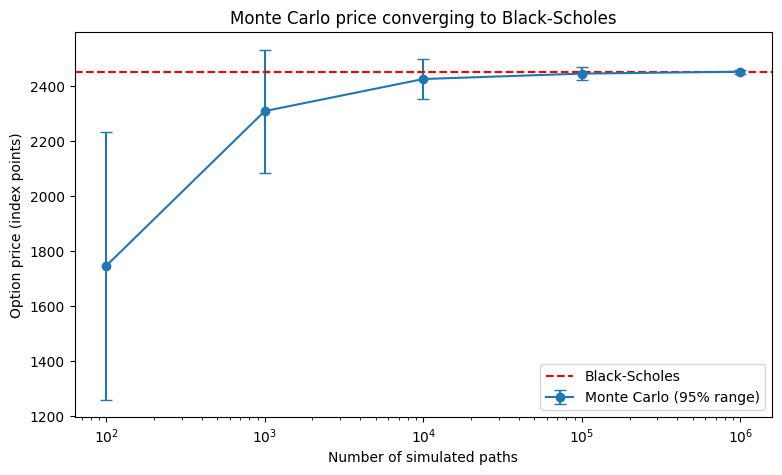

In [ ]:
bs = black_scholes_call(S0, K, T, r, sigma)
sizes = [100, 1000, 10000, 100000, 1000000]

mc_prices = []
ses = []
for n in sizes:
    p, se = monte_carlo_call(S0, K, T, r, sigma, n)
    mc_prices.append(p)
    ses.append(se)

results = pd.DataFrame({
    "Paths": sizes,
    "Monte Carlo price": [round(p, 2) for p in mc_prices],
    "Standard error": [round(s, 2) for s in ses],
    "Black-Scholes price": round(bs, 2),
    "Absolute difference": [round(abs(p - bs), 2) for p in mc_prices],
})
print(results.to_string(index=False))
results.to_csv("option_results.csv", index=False)

plt.figure(figsize=(9, 5))
plt.errorbar(sizes, mc_prices, yerr=[1.96 * s for s in ses],
             fmt="o-", capsize=4, label="Monte Carlo (95% range)")
plt.axhline(bs, color="red", linestyle="--", label="Black-Scholes")
plt.xscale("log")
plt.xlabel("Number of simulated paths")
plt.ylabel("Option price (index points)")
plt.title("Monte Carlo price converging to Black-Scholes")
plt.legend()
plt.savefig("option_convergence.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
from google.colab import files
for f in ["option_convergence.png", "option_results.csv"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download("option_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>